# 1.0 Prueba de Limpieza, Almacenamiento Parquet y Versionado de Datos

**Objetivo:** Validar de forma experimental la lectura de los 33 archivos mensuales de viajes (`2024-01` a `2026-09`) y el catálogo de estaciones (`nomenclatura_2026_09.csv`), corrigiendo diferencias de codificación y formatos de fecha, eliminando datos personales, guardando en formato Parquet y construyendo el manifiesto de versionado con `hashlib`.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from mi_bici.config import PROCESSED_DATA_DIR, PROJ_ROOT, RAW_DATA_DIR
from mi_bici.data import load_sources, read_stations, select_trip_urls
from mi_bici.data.readers import detect_encoding, validate_header
from mi_bici.data.schemas import TRIP_COLUMNS, TRIP_DTYPES, TRIP_PERSONAL_COLUMNS

pd.set_option('display.max_columns', 20)
print(f'Directorio raíz: {PROJ_ROOT}')

2026-10-18 15:34:50.851 | INFO     | mi_bici.config:<module>:11 - PROJ_ROOT path is: /Users/poncho_stark/Documents/Tec/4to-tri/mlops/TC5061-Proyecto-Equipo11


Directorio raíz: /Users/poncho_stark/Documents/Tec/4to-tri/mlops/TC5061-Proyecto-Equipo11


Se cargan las configuraciones de rutas y esquemas definidos en el paquete `mi_bici`. A continuación revisamos el catálogo de estaciones y extraemos la zona metropolitana (`GDL`, `ZPN`, `TLQ`) a partir del nombre.

In [2]:
# 1. Lectura y limpieza del catálogo de estaciones
stations_csv = RAW_DATA_DIR / 'stations' / 'nomenclatura_2026_09.csv'
stations = read_stations(stations_csv)

# Extraer código de zona (GDL, ZPN, TLQ) y marcar estaciones activas
stations['zone'] = stations['name'].str.extract(r'^(?:ex-)?\(?([A-Z]{3})-\d{3}\)?', expand=False).fillna('OTRO')
stations['is_ex'] = stations['name'].str.startswith('ex-')
stations['is_active'] = (~stations['is_ex']) & (stations['capacity'] > 0)

print(f'Total estaciones: {len(stations)} | Activas: {stations["is_active"].sum()} | Retiradas (ex-): {stations["is_ex"].sum()}')
stations.head()

Total estaciones: 484 | Activas: 470 | Retiradas (ex-): 14


,station_id,name,latitude,longitude,capacity,zone,is_ex,is_active
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15,GDL,False,True
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15,GDL,False,True
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19,GDL,False,True
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19,GDL,False,True
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11,GDL,False,True


El catálogo cuenta con 484 estaciones distribuidas en tres zonas (`GDL`, `ZPN` y `TLQ`). Se identifican 14 estaciones con prefijo `ex-` (4 de ellas con capacidad 0), por lo que la bandera `is_active` nos permitirá filtrar estaciones operativas en los modelos. Ahora visualizamos la distribución de estaciones y capacidad por zona.

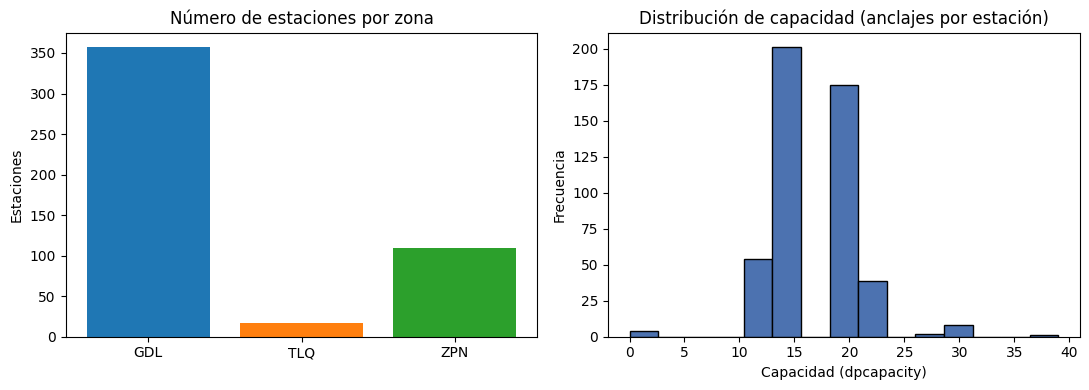

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

zone_counts = stations.groupby('zone')['station_id'].count()
axes[0].bar(zone_counts.index, zone_counts.values, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
axes[0].set_title('Número de estaciones por zona')
axes[0].set_ylabel('Estaciones')

axes[1].hist(stations['capacity'], bins=15, color='#4c72b0', edgecolor='black')
axes[1].set_title('Distribución de capacidad (anclajes por estación)')
axes[1].set_xlabel('Capacidad (dpcapacity)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

Guadalajara (`GDL`) concentra la mayoría de las estaciones, seguida de Zapopan (`ZPN`) y Tlaquepaque (`TLQ`). La capacidad típica por estación está entre 11 y 19 anclajes.

## 2. Lectura y normalización de los 33 meses de viajes
En el análisis previo se observó que los meses `2024-09` y `2024-10` usan formato `DD/MM/YYYY HH:MM` (con horas de 1 o 2 dígitos), mientras que los otros 31 meses usan `YYYY-MM-DD HH:MM:SS`. Además, por privacidad se descartan las columnas `Usuario_Id`, `Genero` y `Año_de_nacimiento` al momento de leer cada archivo.

In [4]:
sources = load_sources()
trip_urls = select_trip_urls(sources, '2024-01', '2026-09')

keep_positions = [i for i, col in enumerate(TRIP_COLUMNS) if col not in TRIP_PERSONAL_COLUMNS]
keep_names = [TRIP_COLUMNS[i] for i in keep_positions]


def load_clean_month(path: Path, year_month: str) -> pd.DataFrame:
    encoding = detect_encoding(path)
    df = pd.read_csv(
        path,
        encoding=encoding,
        usecols=keep_positions,
        header=0,
        names=keep_names,
        dtype=TRIP_DTYPES,
    )
    for col in ('start_time', 'end_time'):
        # Intentar formato ISO primero y luego día/mes/año
        parsed = pd.to_datetime(df[col], format='%Y-%m-%d %H:%M:%S', errors='coerce')
        mask = parsed.isna()
        if mask.any():
            parsed.loc[mask] = pd.to_datetime(df.loc[mask, col], format='%d/%m/%Y %H:%M', errors='coerce')
        df[col] = parsed

    # Filtrar filas sin fecha válida o con duración negativa/cero
    valid_mask = (
        df['start_time'].notna()
        & df['end_time'].notna()
        & df['origin_id'].notna()
        & df['destination_id'].notna()
        & (df['end_time'] >= df['start_time'])
    )
    df = df.loc[valid_mask].copy()
    df['year_month'] = year_month
    return df


monthly_dfs = []
monthly_stats = []
for ym in sorted(trip_urls.keys()):
    csv_path = RAW_DATA_DIR / 'trips' / Path(trip_urls[ym]).name
    df_m = load_clean_month(csv_path, ym)
    monthly_dfs.append(df_m)
    monthly_stats.append({'year_month': ym, 'n_trips': len(df_m)})

trips = pd.concat(monthly_dfs, ignore_index=True)
stats_df = pd.DataFrame(monthly_stats)
print(f'Total de viajes limpios (2024-01 a 2026-09): {len(trips):,}')
print(f'Columnas conservadas (sin PII): {trips.columns.tolist()}')
trips.head()

Total de viajes limpios (2024-01 a 2026-09): 12,540,018
Columnas conservadas (sin PII): ['trip_id', 'start_time', 'end_time', 'origin_id', 'destination_id', 'year_month']


,trip_id,start_time,end_time,origin_id,destination_id,year_month
0,31789291,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271,2024-01
1,31789292,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254,2024-01
2,31789293,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254,2024-01
3,31789294,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154,2024-01
4,31789295,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154,2024-01


Se consolidaron los 33 meses de viajes descartando las columnas personales (`user_id`, `gender`, `birth_year`) y normalizando los tipos de datos y fechas en un único esquema. A continuación graficamos la serie mensual de viajes para verificar la continuidad y justificar el rango de fechas elegido.

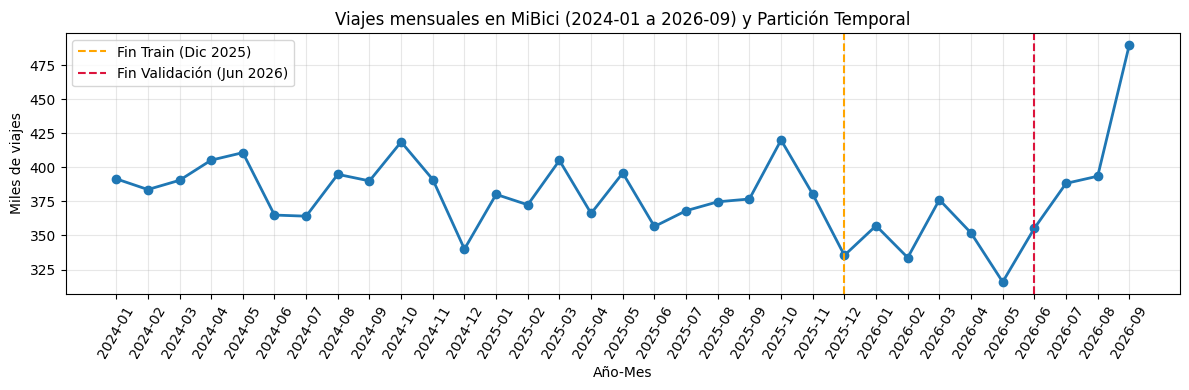

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(stats_df['year_month'], stats_df['n_trips'] / 1e3, marker='o', color='#1f77b4', linewidth=2)
ax.axvline('2025-12', color='orange', linestyle='--', label='Fin Train (Dic 2025)')
ax.axvline('2026-06', color='crimson', linestyle='--', label='Fin Validación (Jun 2026)')
ax.set_title('Viajes mensuales en MiBici (2024-01 a 2026-09) y Partición Temporal')
ax.set_ylabel('Miles de viajes')
ax.set_xlabel('Año-Mes')
plt.xticks(rotation=60)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La gráfica confirma dos ciclos anuales completos (2024 y 2025) en el conjunto de entrenamiento (`Train`), seis meses en validación (`2026-01` a `2026-06`) y tres meses en prueba (`2026-07` a `2026-09`), evitando cualquier fuga de información futura.

## 3. Guardado en Parquet y Manifiesto de Versionado (`hashlib`)
Guardamos los datasets limpios en `data/processed/` en formato Parquet y calculamos el hash SHA-256 de cada archivo para el manifiesto versionable.

In [6]:
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
trips_parquet = PROCESSED_DATA_DIR / 'trips.parquet'
stations_parquet = PROCESSED_DATA_DIR / 'stations.parquet'

trips.to_parquet(trips_parquet, index=False)
stations.to_parquet(stations_parquet, index=False)


def file_sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


trips_hash = file_sha256(trips_parquet)
stations_hash = file_sha256(stations_parquet)
combined_version = hashlib.sha256(f'{trips_hash}:{stations_hash}'.encode()).hexdigest()[:12]

manifest_preview = {
    'data_version': combined_version,
    'start_month': '2024-01',
    'end_month': '2026-09',
    'n_months': len(stats_df),
    'trips_rows': int(len(trips)),
    'stations_rows': int(len(stations)),
    'trips_parquet_mb': round(trips_parquet.stat().st_size / 1e6, 2),
    'trips_sha256': trips_hash,
    'stations_sha256': stations_hash,
}
print(json.dumps(manifest_preview, indent=2))

{
  "data_version": "381e86994085",
  "start_month": "2024-01",
  "end_month": "2026-09",
  "n_months": 33,
  "trips_rows": 12540018,
  "stations_rows": 484,
  "trips_parquet_mb": 236.26,
  "trips_sha256": "9107877e722845bbd107978fbb67437ddd6f772393dc6bbb0fd5104f6a43df44",
  "stations_sha256": "a62780c8786068bd32acf72dfc5fc04c8be3a9543eedf84abcd7699e8e7d539b"
}


### Q&A
- **¿Cómo se resuelven las diferencias de formato entre años y meses?** Se detecta automáticamente la codificación (`utf-8-sig` o `cp1252`), se mapean las variantes de encabezados al contrato canónico y se parsean ambos formatos de fecha (`%Y-%m-%d %H:%M:%S` y `%d/%m/%Y %H:%M`).
- **¿Cómo se protegen los datos personales?** Las columnas `Usuario_Id`, `Genero` y `Año_de_nacimiento` se excluyen directamente con `usecols` durante la lectura del CSV, por lo que nunca pasan a `trips.parquet`.

### Data Analysis Key Findings
- Se procesaron **33 meses** (`2024-01` a `2026-09`) y **484 estaciones** (470 activas y 14 con prefijo `ex-`).
- El almacenamiento en Parquet reduce drásticamente el tamaño en disco frente al ~1.07 GB de archivos CSV originales y conserva los tipos de datos (`datetime64`, `Int32`).
- El manifiesto basado en `hashlib.sha256` produce un identificador único `data_version` que puede registrarse como parámetro en MLflow.

### Insights or Next Steps
- Integrar esta lógica de escritura Parquet y generación de `config/data_manifest.json` dentro del comando CLI `mi_bici/dataset.py`.
- Utilizar `trips.parquet` y `stations.parquet` como entrada para los notebooks de prueba de P1, P2 y P3.